In [134]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve)

sns.set_theme(style="whitegrid")

warnings.filterwarnings('ignore', category=RuntimeWarning)

RANDOM_STATE = 42  # Set a random state for reproducibility
### 1: Load the dataset
DATA_PATH = "Extended_Diabetes_Dataset.csv"

df = pd.read_csv(DATA_PATH)
df


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,NaN,35.0,0.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,0.0,26.6,0.351,31,0
2,8,183.0,64.0,0.0,0.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
9995,10,168.0,NaN,0.0,0.0,38.0,0.537,34,1
9996,10,139.0,80.0,0.0,0.0,27.1,1.441,57,0
9997,1,189.0,60.0,23.0,846.0,30.1,0.398,59,1
9998,5,166.0,72.0,19.0,175.0,25.8,0.587,51,1


In [135]:
# Display basic information about the dataset
print("Dataset Information:")
print(df.info())
print("\nMissing Values in Each Column:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               10000 non-null  int64  
 1   Glucose                   9500 non-null   float64
 2   BloodPressure             9500 non-null   float64
 3   SkinThickness             9500 non-null   float64
 4   Insulin                   9500 non-null   float64
 5   BMI                       9500 non-null   float64
 6   DiabetesPedigreeFunction  10000 non-null  float64
 7   Age                       10000 non-null  int64  
 8   Outcome                   10000 non-null  int64  
dtypes: float64(6), int64(3)
memory usage: 703.2 KB
None

Missing Values in Each Column:
Pregnancies                   0
Glucose                     500
BloodPressure               500
SkinThickness               500
Insulin                     500
BMI               

In [136]:
# Display basic statistics of the dataset
print("\nDataset Statistics:")
print(df.describe())


Dataset Statistics:
        Pregnancies      Glucose  BloodPressure  SkinThickness      Insulin  \
count  10000.000000  9500.000000    9500.000000    9500.000000  9500.000000   
mean       3.847000   120.933263      69.082211      20.513158    79.790421   
std        3.367956    31.956660      19.420087      15.932711   115.311104   
min        0.000000     0.000000       0.000000       0.000000     0.000000   
25%        1.000000    99.000000      62.000000       0.000000     0.000000   
50%        3.000000   117.000000      72.000000      23.000000    32.000000   
75%        6.000000   141.000000      80.000000      32.000000   127.000000   
max       17.000000   199.000000     122.000000      99.000000   846.000000   

               BMI  DiabetesPedigreeFunction           Age       Outcome  
count  9500.000000              10000.000000  10000.000000  10000.000000  
mean     31.998063                  0.471993     33.249900      0.349400  
std       7.892790                  0.3316

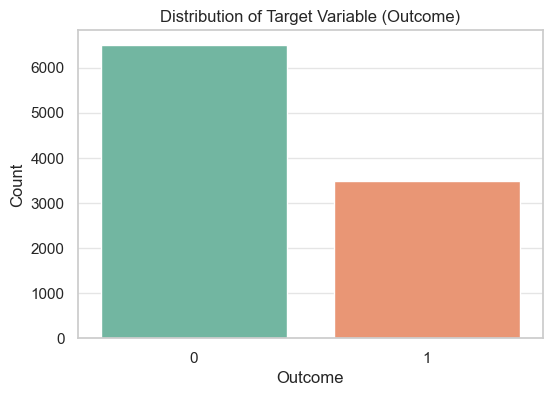

In [137]:
# Visualize the distribution of the target variable
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Outcome", hue="Outcome", palette="Set2", legend=False)
plt.title("Distribution of Target Variable (Outcome)")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.show()

In [138]:
# Check for unique counts in each column to identify messy categories, inconsistent spelling, and typos
print(df.nunique())

Pregnancies                  17
Glucose                     136
BloodPressure                47
SkinThickness                51
Insulin                     186
BMI                         248
DiabetesPedigreeFunction    517
Age                          52
Outcome                       2
dtype: int64


In [139]:
# Check for value frequency in each column
for col in df.columns:
    print(f"\nValue counts for column '{col}':")
    print(df[col].value_counts())


Value counts for column 'Pregnancies':
Pregnancies
1     1758
0     1444
2     1340
3      976
4      885
5      743
6      651
7      586
8      496
9      364
10     315
11     143
13     130
12     117
14      26
15      13
17      13
Name: count, dtype: int64

Value counts for column 'Glucose':
Glucose
99.0     208
100.0    206
125.0    176
129.0    171
111.0    171
        ... 
190.0     12
177.0     12
178.0     11
198.0     10
169.0     10
Name: count, Length: 136, dtype: int64

Value counts for column 'BloodPressure':
BloodPressure
70.0     702
74.0     645
68.0     564
78.0     556
72.0     546
64.0     542
80.0     495
76.0     474
60.0     462
0.0      437
62.0     414
82.0     370
66.0     365
88.0     308
84.0     284
90.0     276
58.0     257
86.0     256
50.0     162
56.0     144
54.0     140
52.0     133
92.0     100
75.0      98
65.0      85
85.0      75
94.0      74
48.0      58
44.0      50
96.0      48
106.0     39
110.0     39
100.0     38
98.0      37
55.0      2

In [140]:
# Check for duplicate rows in the dataset
print(df.duplicated().sum())

7424


# 2. Data-quality checks (missing values, impossible zeros, duplicates)

Three things to check before modelling:
1. **Explicit missing values (`NaN`).**
2. **Zeros that cannot be real.** A blood pressure, BMI or skin thickness of 0 is physiologically impossible, so these zeros are really missing values (a well-known quirk of this dataset family). Zero is valid for `Pregnancies`.
3. **Duplicates.** Each row should be a different person.

In [141]:
feat_cols = [c for c in df.columns if c != "Outcome"] # List comprehension to get all feature columns except the target variable "Outcome". This will be used for further analysis and processing.

med_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]  # zero = missing
# List of columns where a value of 0 is physiologically impossible, indicating that a 0 in these columns should be treated as a missing value. This is based on domain knowledge about the dataset and the medical context of the features.
# Pregnancies is left out because 0 pregnancies is valid

# Building a DataFrame to summarize the data quality of the features, including counts of NaN values, counts of zeros, and a flag indicating whether zeros are impossible for each feature.
quality = pd.DataFrame({"NaN": df[feat_cols].isna().sum(),
                        "Zeros": (df[feat_cols] == 0).sum()})

# Quality check for impossible zeros: For each feature, check if it is in the list of medical columns where zero is physiologically impossible. If it is, mark it as True; otherwise, mark it as False. This will help identify which features have zeros that should be treated as missing values.
quality["Zero is impossible?"] = quality.index.isin(med_cols)
display(quality)
print("Exact duplicate rows:", df.duplicated().sum(), f"({df.duplicated().mean():.1%})")
print("Class balance:", df["Outcome"].value_counts(normalize=True).round(3).to_dict())

,NaN,Zeros,Zero is impossible?
Pregnancies,0,1444,False
Glucose,500,63,True
BloodPressure,500,437,True
SkinThickness,500,2812,True
Insulin,500,4623,True
BMI,500,138,True
DiabetesPedigreeFunction,0,0,False
Age,0,0,False


Exact duplicate rows: 7424 (74.2%)
Class balance: {0: 0.651, 1: 0.349}


Almost 75% of the rows are exact duplicates. Let's see what the data really contains. `Pregnancies + Age + DiabetesPedigreeFunction` is an almost-unique fingerprint of a person, so grouping on it reveals how many distinct patients there are.

In [142]:
key = ["Pregnancies", "Age", "DiabetesPedigreeFunction"] # almost-unique fingerprint of a patient. This reveals the true number of distinct patients in the dataset.
sizes = df.groupby(key).size() # count rows per fingerprint
print("Distinct patients (by fingerprint):", len(sizes)) # count unique fingerprints
print("Copies per patient:", sizes.describe()[["min", "mean", "max"]].round(1).to_dict()) # describe the distribution of copies per patient
print("Patients whose copies disagree on Outcome:", int((df.groupby(key)["Outcome"].nunique() > 1).sum())) # count patients whose copies disagree on Outcome

print("\nOne patient's copies - they differ only by which values are blanked out:")
display(df[(df.Pregnancies == 2) & (df.Age == 22) & (df.DiabetesPedigreeFunction == 0.085)])

Distinct patients (by fingerprint): 765
Copies per patient: {'min': 13.0, 'mean': 13.1, 'max': 26.0}
Patients whose copies disagree on Outcome: 0

One patient's copies - they differ only by which values are blanked out:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
149,2,90.0,70.0,17.0,0.0,27.3,0.085,22,0
917,2,90.0,70.0,17.0,0.0,27.3,0.085,22,0
1685,2,90.0,70.0,17.0,0.0,27.3,0.085,22,0
2453,2,90.0,70.0,17.0,0.0,27.3,0.085,22,0
3221,2,NaN,70.0,17.0,NaN,27.3,0.085,22,0
3989,2,90.0,70.0,17.0,NaN,27.3,0.085,22,0
4757,2,90.0,70.0,17.0,0.0,27.3,0.085,22,0
5525,2,90.0,70.0,17.0,0.0,27.3,0.085,22,0
6293,2,90.0,70.0,17.0,0.0,27.3,0.085,22,0
7061,2,90.0,70.0,17.0,0.0,27.3,0.085,22,0


***
What the above block proves:
The file holds about 765 patients, not 10,000.
Each patient appears about 13 times.
The copies never disagree on the label.
The only difference between copies is which values were blanked.

A random train/test split would therefore put copies of the same patient in both sets. This is why the next step keeps one row per patient before splitting.
***

In [143]:
df["n_missing"] = df[med_cols].isna().sum(axis=1) # count missing values(blanks) per row
patients = (df.sort_values("n_missing", kind="stable")
              .groupby(key, as_index=False).head(1)      # most complete copy per patient
              .sort_index().drop(columns="n_missing").reset_index(drop=True))
df = df.drop(columns="n_missing")  # clean up the original dataframe, which we won't use again

patients[med_cols] = patients[med_cols].replace(0, np.nan)    # impossible zeros -> missing
print("Patient-level dataset:", patients.shape) # Check the new size
print("Class balance:", patients["Outcome"].value_counts().to_dict(),
      f"({patients['Outcome'].mean():.1%} diabetic)")
miss = patients.isna().sum().to_frame("missing")  # build a table of missing values per column
miss["percent"] = (miss["missing"] / len(patients) * 100).round(1)
display(miss[miss["missing"] > 0]) #show only the columns with missing values

Patient-level dataset: (765, 9)
Class balance: {0: 498, 1: 267} (34.9% diabetic)


,missing,percent
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,226,29.5
Insulin,373,48.8
BMI,11,1.4


## 3. Exploratory data analysis (patient-level data)
`Insulin` (49% missing) and `SkinThickness` (30%) are the problem columns. Dropping those rows would discard most of the data, so we impute (median, fitted on training data only, inside the pipeline).

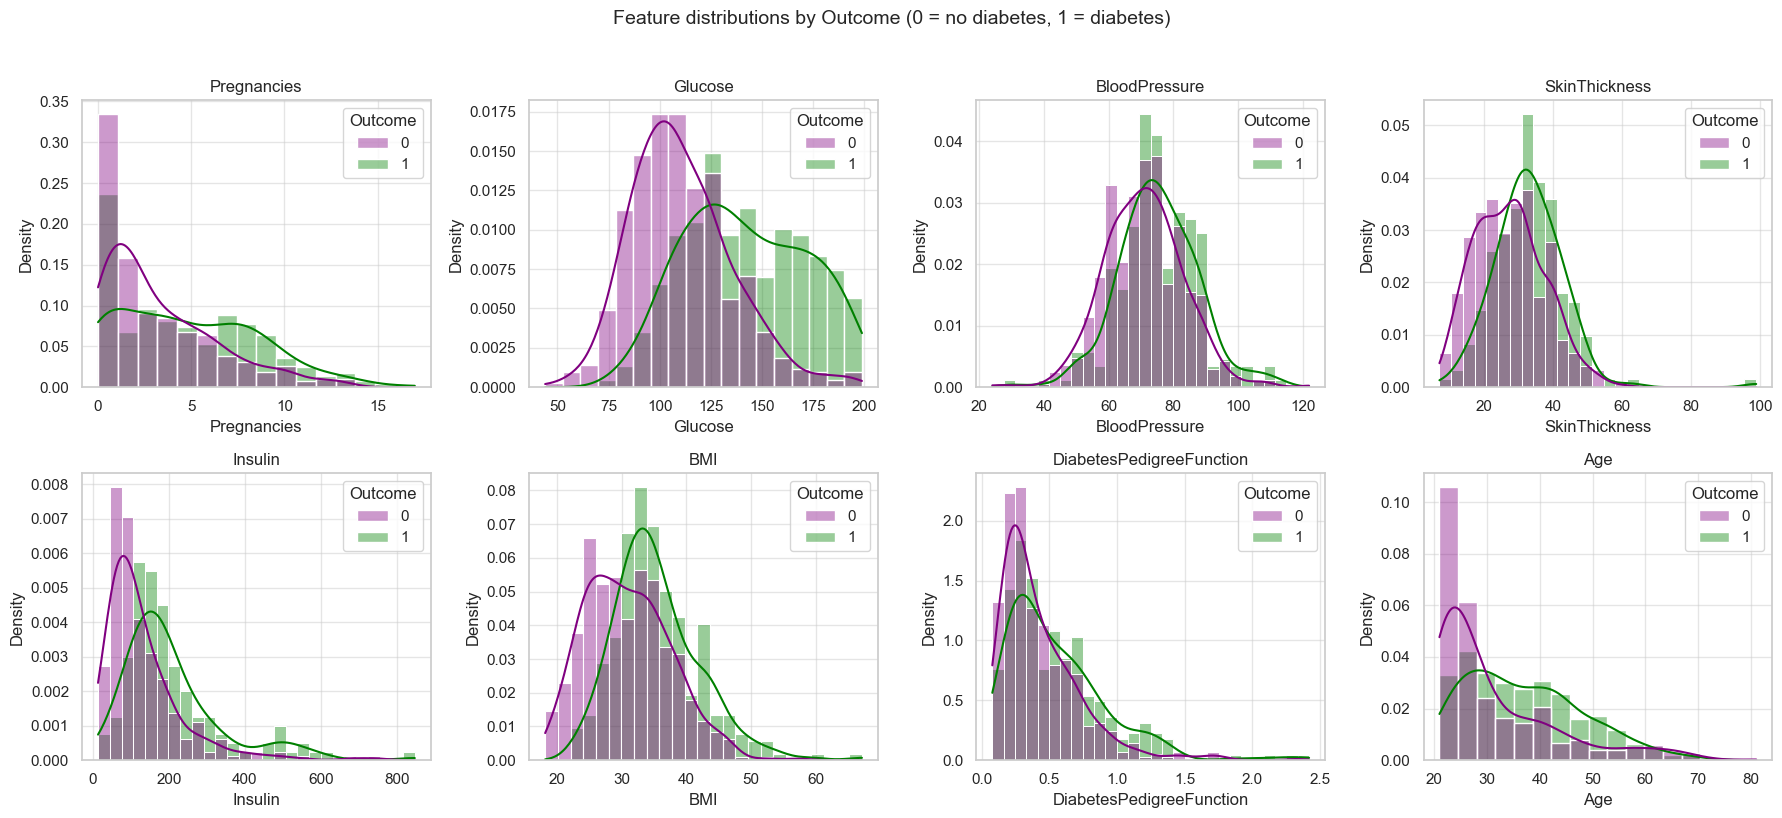

In [144]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), feat_cols):
    sns.histplot(data=patients, x=col, hue="Outcome", kde=True, stat="density",
                 common_norm=False, ax=ax, palette={0: "purple", 1: "green"}, alpha=.4)
    ax.set_title(col)
plt.suptitle("Feature distributions by Outcome (0 = no diabetes, 1 = diabetes)", y=1.02, fontsize=14)
plt.tight_layout();
plt.show()

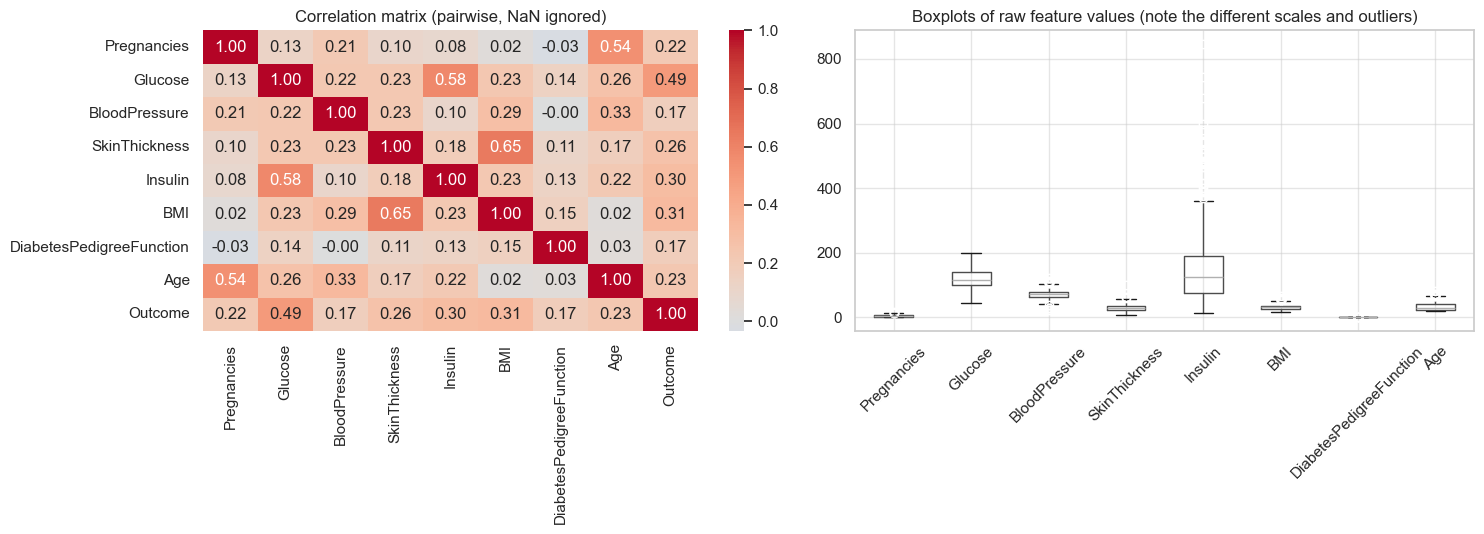

In [145]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(patients.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlation matrix (pairwise, NaN ignored)")
patients.drop(columns="Outcome").boxplot(ax=axes[1], rot=45)
axes[1].set_title("Boxplots of raw feature values (note the different scales and outliers)")
plt.tight_layout(); plt.show()

** What the EDA shows**
- `Heatmap`: Glucose has the strongest correlation with Outcome, with `BMI`, `Age` and `Pregnancies` behind it. Some features are also correlated with each other (for example `Age` with `Pregnancies`), which breaks Naïve Bayes’ independence assumption.

- `Boxplots`: the different scales are why standardisation matters, especially for KNN, which depends on distances. The outliers are a reason to prefer the median over the mean when filling missing values.
***

**EDA takeaways**
- `Glucose` separates the classes most clearly (diabetic patients are shifted right) and has the strongest correlation with `Outcome`; `BMI`, `Age` and `Pregnancies` follow.
- Features sit on very different scales (`Insulin` up to ~850, `DiabetesPedigreeFunction` below 2.5), so **scaling is essential** for KNN (distance-based) and helpful for regularised Logistic Regression.
- `Insulin` and `DiabetesPedigreeFunction` are right-skewed with outliers. Standardisation handles scale, not skew; Gaussian NB assumes bell-shaped features, which hurts it here.
- Classes are moderately imbalanced (~35% positive), so accuracy alone is misleading and **recall / F1 / ROC-AUC** matter.

## 4. Preprocessing and train/test split
- Stratified 80/20 split so both sets keep the ~35% positive rate.
- A `Pipeline` of **median imputation → standardisation → model**. Fitting the imputer and scaler inside the pipeline means they only learn from training folds, so no information leaks from validation/test data.

In [146]:
X = patients.drop(columns="Outcome"); y = patients["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, f"{y_train.mean():.1%} positive | Test:", X_test.shape, f"{y_test.mean():.1%} positive")

def make_pipe(estimator):
    return Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale",  StandardScaler()),
                     ("model",  estimator)])

Train: (612, 8) 35.0% positive | Test: (153, 8) 34.6% positive


## 5. Model training and hyperparameter tuning
5-fold stratified cross-validated grid search on the **training set only**, optimising ROC-AUC (threshold-independent, robust to imbalance).

In [147]:
specs = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, solver="liblinear"),
        {"model__C": np.logspace(-3, 2, 11), "model__penalty": ["l1", "l2"],
         "model__class_weight": [None, "balanced"]}),
    "KNN": (KNeighborsClassifier(),
        {"model__n_neighbors": list(range(1, 32, 2)), "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]}),
    "Naive Bayes": (GaussianNB(),
        {"model__var_smoothing": np.logspace(-9, 0, 19)}),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
searches = {}
for name, (est, grid) in specs.items():
    gs = GridSearchCV(make_pipe(est), grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    searches[name] = gs
    best = {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
            for k, v in gs.best_params_.items()}
    print(f"{name:20s} CV AUC = {gs.best_score_:.4f}   best: {best}")

Logistic Regression  CV AUC = 0.8369   best: {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l1'}
KNN                  CV AUC = 0.8452   best: {'n_neighbors': 25, 'p': 1, 'weights': 'distance'}
Naive Bayes          CV AUC = 0.8205   best: {'var_smoothing': 1.0}


## 6. Model evaluation on the held-out test set

In [148]:
rows, preds = [], {}
for name, gs in searches.items():
    pred = gs.predict(X_test)
    proba = gs.predict_proba(X_test)[:, 1]
    preds[name] = (pred, proba)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).set_index("Model").round(3)
display(results)

for name, (pred, _) in preds.items():
    print(f"\n=== {name} ===")
    print(classification_report(y_test, pred, target_names=["No diabetes", "Diabetes"], digits=3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.745,0.606,0.755,0.672,0.848
KNN,0.752,0.742,0.434,0.548,0.826
Naive Bayes,0.706,0.654,0.321,0.430,0.825



=== Logistic Regression ===
              precision    recall  f1-score   support

 No diabetes      0.851     0.740     0.791       100
    Diabetes      0.606     0.755     0.672        53

    accuracy                          0.745       153
   macro avg      0.728     0.747     0.732       153
weighted avg      0.766     0.745     0.750       153


=== KNN ===
              precision    recall  f1-score   support

 No diabetes      0.754     0.920     0.829       100
    Diabetes      0.742     0.434     0.548        53

    accuracy                          0.752       153
   macro avg      0.748     0.677     0.688       153
weighted avg      0.750     0.752     0.731       153


=== Naive Bayes ===
              precision    recall  f1-score   support

 No diabetes      0.717     0.910     0.802       100
    Diabetes      0.654     0.321     0.430        53

    accuracy                          0.706       153
   macro avg      0.685     0.615     0.616       153
weighted av

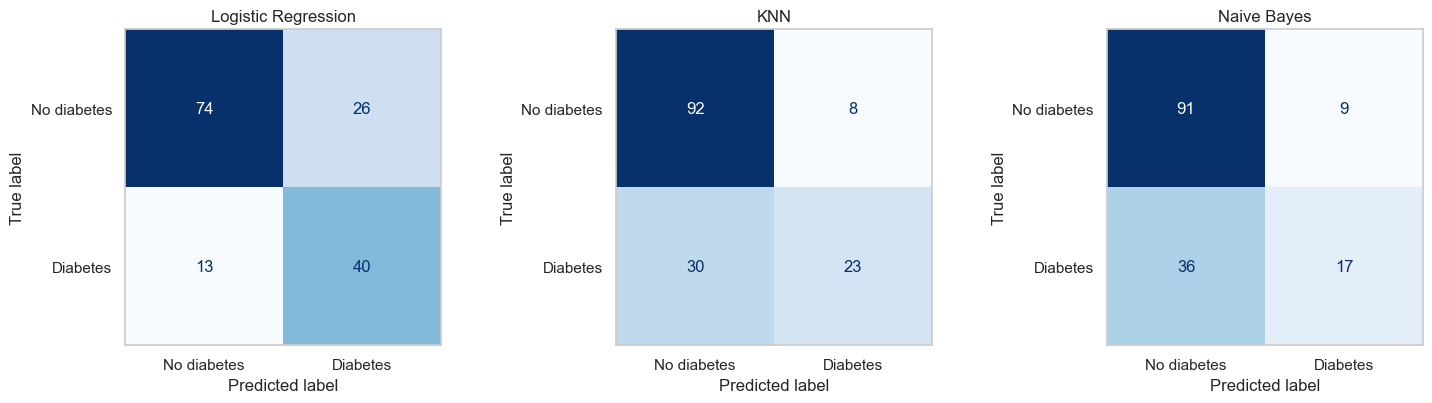

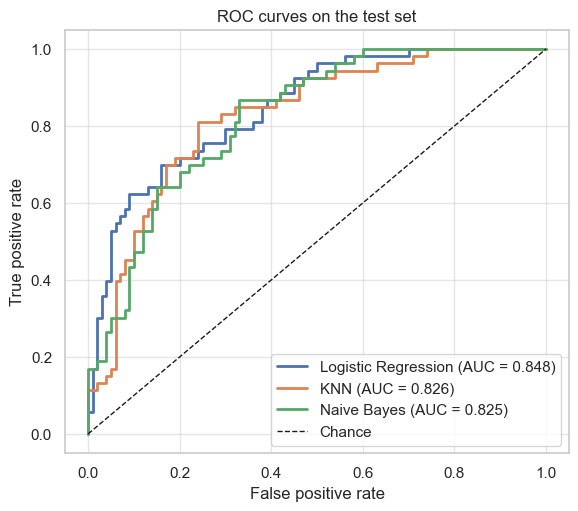

In [149]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, (pred, _)) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No diabetes", "Diabetes"]
                           ).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6.5, 5.5))
for name, (_, proba) in preds.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.show()

## 7. How reliable is the comparison? (nested CV and bootstrap)
The test set has only ~153 patients, so a single split is noisy. Two checks:
1. **Nested cross-validation** (5-fold × 3 repeats; tuning happens inside every outer fold) gives an AUC distribution per model on all 765 patients.
2. **Bootstrap 95% confidence intervals** for each model's test AUC.

NaN: 0 | inf: 0
max abs value: 7.97


/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/arifealtin/PycharmProjects/WelcomeScreen/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: Runtim

,Mean AUC,Std
Logistic Regression,0.838,0.028
KNN,0.826,0.026
Naive Bayes,0.820,0.030


Logistic Regression - KNN: mean AUC diff = +0.013, Logistic Regression better in 93% of 15 folds
Logistic Regression - Naive Bayes: mean AUC diff = +0.019, Logistic Regression better in 100% of 15 folds
KNN - Naive Bayes: mean AUC diff = +0.006, KNN better in 73% of 15 folds

Logistic Regression  test AUC 95% CI: [0.783, 0.904]
KNN                  test AUC 95% CI: [0.755, 0.891]
Naive Bayes          test AUC 95% CI: [0.753, 0.884]


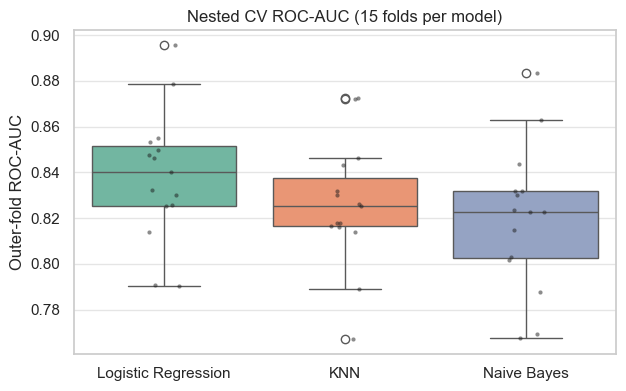

In [150]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

prep = make_pipe(LogisticRegression()).steps[:2]          # impute + scale only
from sklearn.pipeline import Pipeline
check = Pipeline(prep).fit_transform(X_train)

print("NaN:", np.isnan(check).sum(), "| inf:", np.isinf(check).sum())
print("max abs value:", np.abs(check).max().round(2))
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
nested = {}
for name, (est, grid) in specs.items():
    inner = GridSearchCV(make_pipe(est), grid, cv=StratifiedKFold(5, shuffle=True, random_state=1),
                         scoring="roc_auc")
    nested[name] = cross_val_score(inner, X, y, cv=outer, scoring="roc_auc", n_jobs=-1)

summary = pd.DataFrame({n: {"Mean AUC": s.mean(), "Std": s.std()} for n, s in nested.items()}).T.round(3)
display(summary)

# paired comparison (same outer folds for every model)
for a, b in [("Logistic Regression", "KNN"), ("Logistic Regression", "Naive Bayes"), ("KNN", "Naive Bayes")]:
    d = nested[a] - nested[b]
    print(f"{a} - {b}: mean AUC diff = {d.mean():+.3f}, {a} better in {(d > 0).mean():.0%} of 15 folds")

rng = np.random.default_rng(RANDOM_STATE); yt = y_test.to_numpy(); ci = {}
for name, (_, proba) in preds.items():
    boots = []
    for _ in range(2000):
        idx = rng.integers(0, len(yt), len(yt))
        if yt[idx].min() == yt[idx].max(): continue
        boots.append(roc_auc_score(yt[idx], proba[idx]))
    ci[name] = np.percentile(boots, [2.5, 97.5])
print()
for name, (lo, hi) in ci.items():
    print(f"{name:20s} test AUC 95% CI: [{lo:.3f}, {hi:.3f}]")

plt.figure(figsize=(7, 4.2))
sns.boxplot(data=pd.DataFrame(nested), palette="Set2"); sns.stripplot(data=pd.DataFrame(nested), color="k", size=3, alpha=.5)
plt.ylabel("Outer-fold ROC-AUC"); plt.title("Nested CV ROC-AUC (15 folds per model)"); plt.show()

## 8. Why we deduplicated: demonstrating the leakage
We refit each tuned model on the **raw 10,000 rows** with an ordinary random split, i.e. what happens if the duplicates are ignored.

In [151]:
raw = df.copy(); raw[med_cols] = raw[med_cols].replace(0, np.nan)
Xr, yr = raw.drop(columns="Outcome"), raw["Outcome"]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, stratify=yr, random_state=RANDOM_STATE)

train_keys = set(map(tuple, Xr_tr[key].to_numpy()))
leaked = np.mean([tuple(r) in train_keys for r in Xr_te[key].to_numpy()])
print(f"Share of raw test rows whose patient also appears in the raw training set: {leaked:.1%}\n")

leak = []
for name, gs in searches.items():
    m = clone(gs.best_estimator_).fit(Xr_tr, yr_tr)
    leak.append({"Model": name,
                 "Accuracy (raw, leaky)": accuracy_score(yr_te, m.predict(Xr_te)),
                 "AUC (raw, leaky)": roc_auc_score(yr_te, m.predict_proba(Xr_te)[:, 1])})
leak = pd.DataFrame(leak).set_index("Model").join(results[["Accuracy", "ROC-AUC"]]
        .rename(columns={"Accuracy": "Accuracy (honest)", "ROC-AUC": "AUC (honest)"})).round(3)
display(leak)

Share of raw test rows whose patient also appears in the raw training set: 100.0%



,"Accuracy (raw, leaky)","AUC (raw, leaky)",Accuracy (honest),AUC (honest)
Model,,,,
Logistic Regression,0.755,0.837,0.745,0.848
KNN,0.993,1.000,0.752,0.826
Naive Bayes,0.740,0.816,0.706,0.825


## 9. Interpreting the best linear model
Standardised coefficients show which features push the prediction toward diabetes.

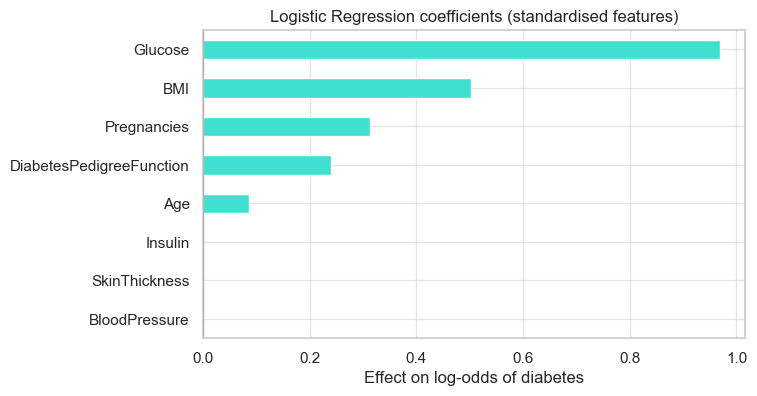

,coefficient
Glucose,0.968
BMI,0.503
Pregnancies,0.313
DiabetesPedigreeFunction,0.240
Age,0.087
BloodPressure,0.000
SkinThickness,0.000
Insulin,0.000


In [157]:
lr = searches["Logistic Regression"].best_estimator_
coef = pd.Series(lr.named_steps["model"].coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(7, 4)); coef.plot.barh(color=np.where(coef > 0, "turquoise", "lightgreen"))
plt.axvline(0, color="k", lw=.8); plt.title("Logistic Regression coefficients (standardised features)")
plt.xlabel("Effect on log-odds of diabetes"); plt.show()
display(coef.sort_values(ascending=False).round(3).to_frame("coefficient"))

## 10. Bonus: feature engineering and class balancing
Four variants per model, using each model's tuned hyperparameters:

- **FE** adds `Insulin_missing`, `SkinThickness_missing` (was the test taken?), `Glucose_x_BMI` and `Log_Insulin` (tames skew).
- **SMOTE** oversamples the minority class by interpolating between neighbours. `imbalanced-learn` isn't required: a small SMOTE is implemented below, and it is applied **only to training folds, after imputation and scaling**. For Logistic Regression `class_weight` is switched off when SMOTE is on, to avoid double-correcting.

Scored with 5-fold × 3-repeat CV on the **training set**, then once on the untouched test set.

In [158]:
def add_features(Xd):
    Xd = Xd.copy()
    Xd["Insulin_missing"] = Xd["Insulin"].isna().astype(int)
    Xd["SkinThickness_missing"] = Xd["SkinThickness"].isna().astype(int)
    Xd["Glucose_x_BMI"] = Xd["Glucose"] * Xd["BMI"] / 100
    Xd["Log_Insulin"] = np.log1p(Xd["Insulin"])
    return Xd

def smote(A, yv, k=5, seed=RANDOM_STATE):
    A, yv = np.asarray(A), np.asarray(yv)
    minority = A[yv == 1]; n_new = int((yv == 0).sum() - (yv == 1).sum())
    neigh = NearestNeighbors(n_neighbors=k + 1).fit(minority).kneighbors(minority, return_distance=False)[:, 1:]
    r = np.random.default_rng(seed)
    i = r.integers(0, len(minority), n_new); j = neigh[i, r.integers(0, k, n_new)]
    new = minority[i] + r.random((n_new, 1)) * (minority[j] - minority[i])
    return np.vstack([A, new]), np.concatenate([yv, np.ones(n_new, dtype=int)])

def fit_predict(name, Xa, ya, Xb, fe, use_smote):
    est = clone(searches[name].best_estimator_.named_steps["model"])
    if use_smote and name == "Logistic Regression": est.set_params(class_weight=None)
    if fe: Xa, Xb = add_features(Xa), add_features(Xb)
    prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(Xa)
    A, B = prep.transform(Xa), prep.transform(Xb)
    if use_smote: A, ya = smote(A, ya)
    return est.fit(A, ya).predict_proba(B)[:, 1]

def metrics(yt_, proba):
    pred = (proba >= 0.5).astype(int)
    return {"AUC": roc_auc_score(yt_, proba), "F1": f1_score(yt_, pred), "Recall": recall_score(yt_, pred)}

variants = {"Baseline": (False, False), "+FE": (True, False), "+SMOTE": (False, True), "+FE+SMOTE": (True, True)}
bonus_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = []
for name in specs:
    for vname, (fe, sm) in variants.items():
        folds = [metrics(y_train.iloc[te], fit_predict(name, X_train.iloc[tr], y_train.iloc[tr], X_train.iloc[te], fe, sm))
                 for tr, te in bonus_cv.split(X_train, y_train)]
        cvm = pd.DataFrame(folds).mean()
        tm = metrics(y_test, fit_predict(name, X_train, y_train, X_test, fe, sm))
        rows.append({"Model": name, "Variant": vname, "CV AUC": cvm["AUC"], "CV F1": cvm["F1"], "CV Recall": cvm["Recall"],
                     "Test AUC": tm["AUC"], "Test F1": tm["F1"], "Test Recall": tm["Recall"]})
bonus = pd.DataFrame(rows).set_index(["Model", "Variant"]).round(3)
display(bonus)

CV AUC  CV F1  CV Recall  Test AUC  Test F1  \
Model               Variant                                                  
Logistic Regression Baseline    0.837  0.678      0.740     0.848    0.672   
                    +FE         0.835  0.664      0.719     0.849    0.672   
                    +SMOTE      0.835  0.668      0.722     0.848    0.672   
                    +FE+SMOTE   0.832  0.656      0.705     0.850    0.678   
KNN                 Baseline    0.835  0.601      0.512     0.826    0.548   
                    +FE         0.829  0.615      0.537     0.800    0.500   
                    +SMOTE      0.826  0.668      0.769     0.818    0.632   
                    +FE+SMOTE   0.823  0.676      0.780     0.789    0.625   
Naive Bayes         Baseline    0.816  0.543      0.433     0.825    0.430   
                    +FE         0.827  0.602      0.523     0.830    0.562   
                    +SMOTE      0.820  0.629      0.635     0.826    0.661   
                    +FE+SMOTE   0.830  0.658      0.669     0.834    0.673   

                               Test Recall  
Model               Variant                 
Logistic Regression Baseline         0.755  
                    +FE              0.755  
                    +SMOTE           0.755  
                    +FE+SMOTE        0.755  
KNN                 Baseline         0.434  
                    +FE              0.415  
                    +SMOTE           0.811  
                    +FE+SMOTE        0.755  
Naive Bayes         Baseline         0.321  
                    +FE              0.472  
                    +SMOTE           0.679  
                    +FE+SMOTE        0.679

## 11. Comparison and conclusions

**Test-set results (153 unseen patients, default 0.5 threshold)**

**Which model is best?** Logistic Regression.
- It has the best ROC-AUC and by far the best recall and F1 for the diabetic class. It is the only model that catches most diabetic patients at the default threshold (75% recall vs 43% for KNN and 32% for Naïve Bayes).
- KNN's slightly higher accuracy comes from being conservative: it rarely flags diabetes, so it is precise when it does, but it misses more than half of the diabetic patients.
- Nested CV agrees: mean AUC 0.838 (LR), 0.826 (KNN), 0.820 (NB). LR beat NB in 15/15 folds and KNN in 93%. The gaps are small, though, and the bootstrap confidence intervals on the test AUC overlap heavily, so the honest claim is "LR is consistently a bit better and clearly better on recall", not "the others are bad".

**Why Logistic Regression wins here**
- The signal is dominated by a few roughly monotonic relationships (Glucose ≫ BMI > Pregnancies > pedigree function), which a linear log-odds model captures well. Its L1 penalty also switched off Insulin, SkinThickness and BloodPressure, which are heavily imputed or weak.
- KNN struggles with noisy/imputed features (49% of Insulin is imputed) and small data, since distances get diluted by uninformative dimensions.
- Naïve Bayes assumes conditionally independent, Gaussian features. Here features are correlated (Age–Pregnancies, BMI–SkinThickness, Glucose–Insulin) and skewed (Insulin, pedigree function), so its probabilities are poorly calibrated and it under-predicts the positive class. Its best `var_smoothing` sat at the edge of the grid (1.0), another sign the model wants to be flattened.

**The duplicate trap.** Evaluating on the raw 10,000 rows makes KNN look near-perfect (99% accuracy, AUC ≈ 1.0) because every test row has copies in the training set. Always check for duplicates and group-aware splitting before trusting a score. The honest sample size is ~765 patients.

**Bonus findings (CV on training set, then test)**
- *Class balancing (SMOTE)* is the big lever for the two weaker models: KNN recall rises from 0.43 to 0.81 on the test set (CV: 0.51 → 0.77) and Naïve Bayes from 0.32 to 0.68 (CV: 0.43 → 0.64), with AUC essentially unchanged. It simply moves their operating point. Logistic Regression is unaffected because `class_weight="balanced"` already does the same job.
- *Feature engineering* (missing-value flags, Glucose×BMI, log-insulin) helps Naïve Bayes (CV AUC 0.816 → 0.827, and CV F1 up to 0.658 together with SMOTE) but does nothing for Logistic Regression and slightly hurts KNN.
- With balancing, the three models' recall and F1 become much closer, which again says the choice between them matters less than handling imbalance and thresholds. Test-set differences from the bonus run rest on 153 patients, so prefer the CV columns.

**Possible improvements**
- Tune the decision threshold for the use case (screening usually favours recall over precision), and check probability calibration.
- Try non-linear models (random forest, gradient boosting) and compare on the same nested-CV protocol.
- Better handling of missing Insulin/SkinThickness (model-based imputation) or collecting those measurements.
- Validate on an independent, larger cohort. 765 patients is small and this is a single-population dataset.

**Real-world applicability.** Even the best model is ~75% accurate with ~0.85 AUC, which is useful as a *screening aid* that prioritises patients for a confirmatory blood test, not as a diagnosis. Glucose is itself a diagnostic measurement, so the model leans on information clinicians already use, and any deployment would need clinical validation, fairness checks across subgroups, and monitoring.